# Fase 4 — Notebook 3: Fusão Multimodal e Alerta Clínico

**Objetivo:** Integrar os resultados da análise de áudio e vídeo para gerar um diagnóstico consolidado e um alerta automático para a equipe médica.

**Pipeline:**
1. Carrega resultados dos notebooks anteriores (áudio + vídeo)
2. Fusão multimodal — combina os sinais de risco
3. Calcula score de risco consolidado
4. Gera relatório final integrado via Claude API
5. Simula alerta para equipe médica
6. Dashboard final do paciente

## Célula 1 — Imports e configuração

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from datetime import datetime
import anthropic
from dotenv import load_dotenv

warnings.filterwarnings('ignore')

load_dotenv()
ANTHROPIC_API_KEY = os.getenv("ANTHROPIC_API_KEY")
assert ANTHROPIC_API_KEY, "❌ ANTHROPIC_API_KEY não encontrada no .env!"

Path("data/relatorios").mkdir(parents=True, exist_ok=True)

print("✅ Ambiente configurado!")
print(f"   Data/hora : {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")

✅ Ambiente configurado!
   Data/hora : 17/11/2026 18:02:18


## Célula 2 — Carrega resultados dos notebooks anteriores

In [2]:
# Carrega resultados do notebook 01 (áudio)
with open('data/relatorio_audio_p002.json', 'r', encoding='utf-8') as f:
    resultado_audio = json.load(f)

# Carrega resultados do notebook 02 (vídeo)
with open('data/relatorio_video_p001.json', 'r', encoding='utf-8') as f:
    resultado_video = json.load(f)

print("✅ Resultados carregados!")
print("\n📋 RESUMO — ANÁLISE DE ÁUDIO")
print(f"   Paciente         : {resultado_audio['id_paciente']}")
print(f"   Risco geral      : {resultado_audio['risco_geral']}")
print(f"   Sentimento       : {resultado_audio['sentimento']['sentimento']}")
print(f"   Flags ativos     : {resultado_audio['flags_ativos']}/5")
print(f"   Jitter           : {resultado_audio['praat_resumo']['jitter_pct']:.4f}%")
print(f"   HNR              : {resultado_audio['praat_resumo']['hnr_db']:.2f} dB")

print("\n📋 RESUMO — ANÁLISE DE VÍDEO")
print(f"   Paciente         : {resultado_video['id_paciente']}")
print(f"   Duração analisada: {resultado_video['duracao_s']:.1f}s")
print(f"   Taxa de alerta   : {resultado_video['taxa_alerta_pct']:.1f}%")
print(f"   Assimetria média : {resultado_video['media_assimetria_joelhos']:.1f}°")
print(f"   Desnível ombros  : {resultado_video['media_desnivel_ombros']:.4f}")

✅ Resultados carregados!

📋 RESUMO — ANÁLISE DE ÁUDIO
   Paciente         : P002
   Risco geral      : Alto
   Sentimento       : Neutro
   Flags ativos     : 4/5
   Jitter           : 2.1924%
   HNR              : 12.52 dB

📋 RESUMO — ANÁLISE DE VÍDEO
   Paciente         : P001
   Duração analisada: 466.8s
   Taxa de alerta   : 31.6%
   Assimetria média : 21.7°
   Desnível ombros  : 0.0550


## Célula 3 — Motor de fusão multimodal

Cada modalidade contribui com um **score parcial** de risco (0–100).
O score final é a média ponderada dos três scores:
- Áudio vocal (40%): jitter, shimmer, HNR
- Texto/NLP (30%): sentimento, NER
- Vídeo/postura (30%): assimetria, desnível, taxa de alerta

In [3]:
def calcular_score_audio(resultado_audio):
    """
    Calcula score de risco vocal (0–100) a partir das métricas do Praat.
    Quanto maior o score, maior o risco.
    """
    score = 0
    detalhes = []

    p = resultado_audio['praat_resumo']

    # Jitter (normal < 1.04%): contribui até 35 pontos
    if p['jitter_pct'] > 1.04:
        contribuicao = min(35, (p['jitter_pct'] - 1.04) / 1.04 * 35)
        score += contribuicao
        detalhes.append(f"Jitter elevado ({p['jitter_pct']:.4f}%): +{contribuicao:.0f} pts")

    # Shimmer (normal < 3.81%): contribui até 35 pontos
    if p['shimmer_pct'] > 3.81:
        contribuicao = min(35, (p['shimmer_pct'] - 3.81) / 3.81 * 35)
        score += contribuicao
        detalhes.append(f"Shimmer elevado ({p['shimmer_pct']:.4f}%): +{contribuicao:.0f} pts")

    # HNR (normal > 20 dB): contribui até 30 pontos
    if 0 < p['hnr_db'] < 20:
        contribuicao = min(30, (20 - p['hnr_db']) / 20 * 30)
        score += contribuicao
        detalhes.append(f"HNR baixo ({p['hnr_db']:.2f} dB): +{contribuicao:.0f} pts")

    return min(100, round(score, 1)), detalhes


def calcular_score_nlp(resultado_audio):
    """
    Calcula score de risco textual (0–100) a partir de sentimento e NER.
    """
    score = 0
    detalhes = []

    s = resultado_audio['sentimento']
    n = resultado_audio['ner']

    # Sentimento negativo: 40 pts
    if s['risco_sentimento'] == 'Alto':
        score += 40
        detalhes.append(f"Sentimento negativo ({s['sentimento']}, {s['confianca_pct']}%): +40 pts")
    elif s['sentimento'] == 'Neutro':
        score += 10
        detalhes.append(f"Sentimento neutro: +10 pts")

    # Entidades médicas detectadas: até 30 pts
    n_entidades = len(n.get('entidades_bio', []))
    if n_entidades > 0:
        contribuicao = min(30, n_entidades * 10)
        score += contribuicao
        detalhes.append(f"{n_entidades} entidade(s) médica(s) detectada(s): +{contribuicao} pts")

    # Termos críticos: até 30 pts
    n_termos = len(n.get('termos_criticos', []))
    if n_termos > 0:
        contribuicao = min(30, n_termos * 10)
        score += contribuicao
        detalhes.append(f"{n_termos} termo(s) crítico(s): +{contribuicao} pts")

    return min(100, round(score, 1)), detalhes


def calcular_score_video(resultado_video):
    """
    Calcula score de risco postural (0–100) a partir das métricas de vídeo.
    """
    score = 0
    detalhes = []

    # Taxa de alertas posturais (frames com ≥2 flags): até 50 pts
    taxa = resultado_video['taxa_alerta_pct']
    if taxa > 0:
        contribuicao = min(50, taxa * 1.5)
        score += contribuicao
        detalhes.append(f"Taxa de alertas posturais ({taxa:.1f}%): +{contribuicao:.0f} pts")

    # Assimetria média dos joelhos: até 30 pts
    assimetria = resultado_video['media_assimetria_joelhos']
    if assimetria > 10:
        contribuicao = min(30, (assimetria - 10) / 20 * 30)
        score += contribuicao
        detalhes.append(f"Assimetria de joelhos ({assimetria:.1f}°): +{contribuicao:.0f} pts")

    # Desnível de ombros: até 20 pts
    desnivel = resultado_video['media_desnivel_ombros']
    if desnivel > 0.03:
        contribuicao = min(20, (desnivel - 0.03) / 0.05 * 20)
        score += contribuicao
        detalhes.append(f"Desnível de ombros ({desnivel:.4f}): +{contribuicao:.0f} pts")

    return min(100, round(score, 1)), detalhes


def classificar_risco(score):
    if score >= 60:
        return 'Alto',  '🔴'
    elif score >= 30:
        return 'Médio', '🟡'
    else:
        return 'Baixo', '🟢'


# Calcula os três scores
score_audio, det_audio = calcular_score_audio(resultado_audio)
score_nlp,   det_nlp   = calcular_score_nlp(resultado_audio)
score_video, det_video = calcular_score_video(resultado_video)

# Score final ponderado
PESO_AUDIO = 0.40
PESO_NLP   = 0.30
PESO_VIDEO = 0.30

score_final = round(
    score_audio * PESO_AUDIO +
    score_nlp   * PESO_NLP   +
    score_video * PESO_VIDEO,
    1
)

risco_final, emoji_final = classificar_risco(score_final)

print("🧮 FUSÃO MULTIMODAL — SCORES DE RISCO")
print("=" * 55)
print(f"   Score Áudio (40%) : {score_audio:5.1f} pts  — {classificar_risco(score_audio)[1]} {classificar_risco(score_audio)[0]}")
for d in det_audio:
    print(f"      ↳ {d}")
print(f"   Score NLP   (30%) : {score_nlp:5.1f} pts  — {classificar_risco(score_nlp)[1]} {classificar_risco(score_nlp)[0]}")
for d in det_nlp:
    print(f"      ↳ {d}")
print(f"   Score Vídeo (30%) : {score_video:5.1f} pts  — {classificar_risco(score_video)[1]} {classificar_risco(score_video)[0]}")
for d in det_video:
    print(f"      ↳ {d}")
print()
print(f"{'='*55}")
print(f"   {emoji_final} SCORE FINAL       : {score_final:5.1f} pts  → RISCO {risco_final.upper()}")
print(f"{'='*55}")

🧮 FUSÃO MULTIMODAL — SCORES DE RISCO
   Score Áudio (40%) :  81.2 pts  — 🔴 Alto
      ↳ Jitter elevado (2.1924%): +35 pts
      ↳ Shimmer elevado (10.7610%): +35 pts
      ↳ HNR baixo (12.52 dB): +11 pts
   Score NLP   (30%) :  20.0 pts  — 🟢 Baixo
      ↳ Sentimento neutro: +10 pts
      ↳ 1 entidade(s) médica(s) detectada(s): +10 pts
   Score Vídeo (30%) :  74.9 pts  — 🔴 Alto
      ↳ Taxa de alertas posturais (31.6%): +47 pts
      ↳ Assimetria de joelhos (21.7°): +17 pts
      ↳ Desnível de ombros (0.0550): +10 pts

   🔴 SCORE FINAL       :  61.0 pts  → RISCO ALTO


## Célula 4 — Dashboard de fusão multimodal

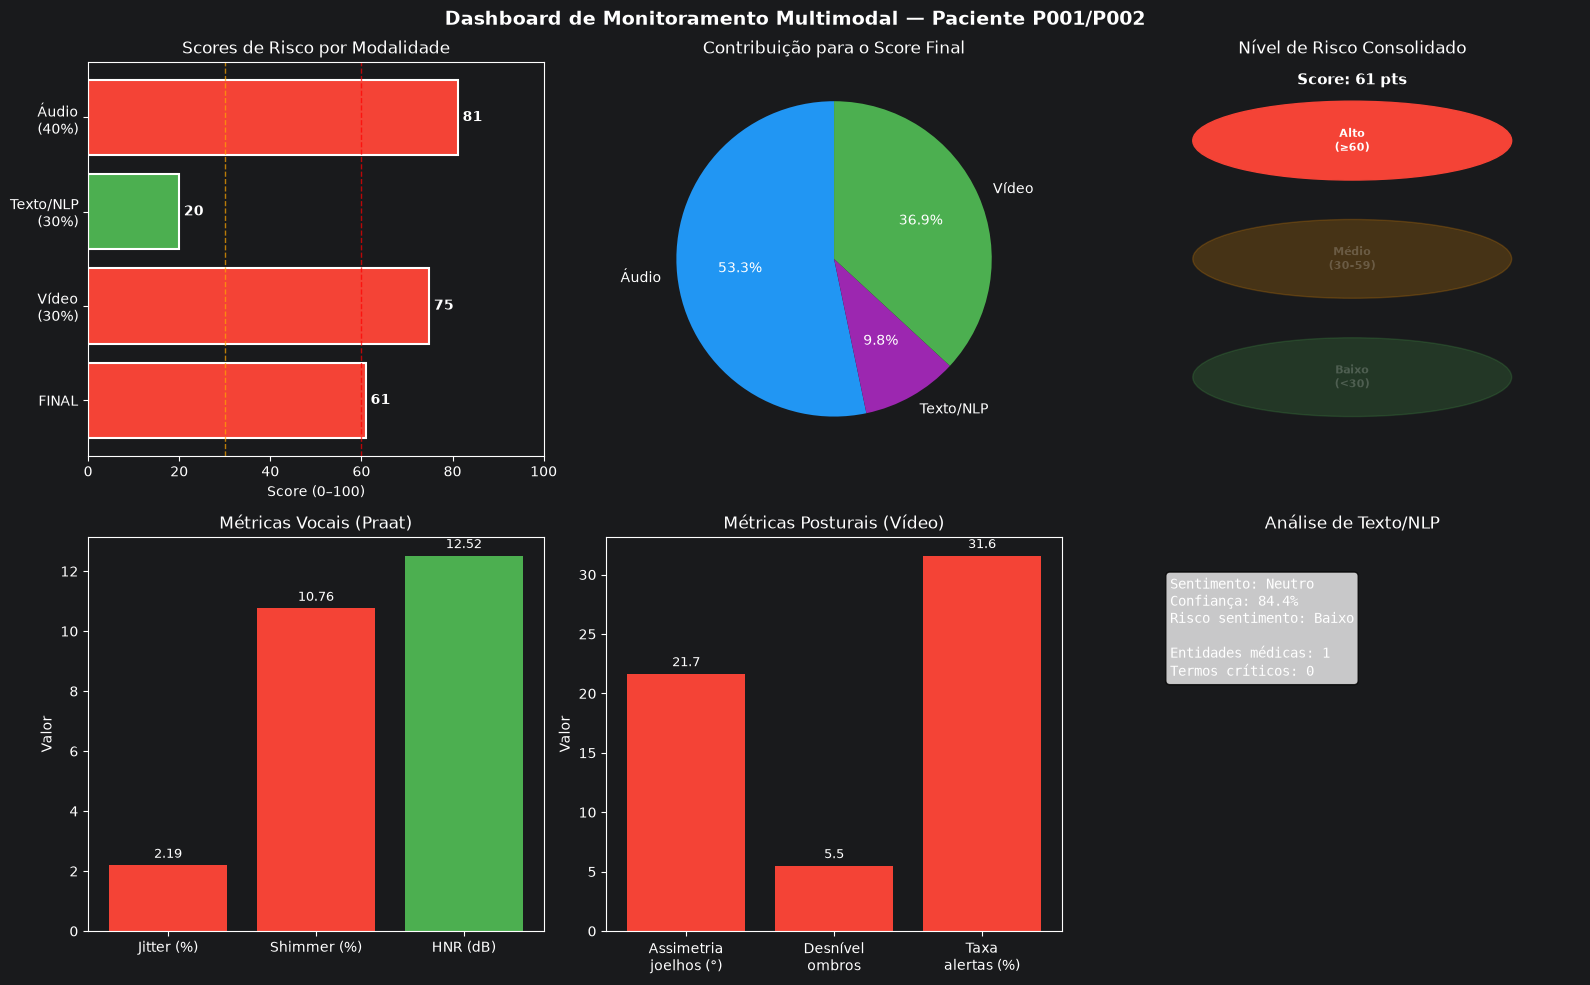

✅ Dashboard de fusão salvo em data/relatorios/11_dashboard_fusao.png


In [4]:
fig = plt.figure(figsize=(16, 10))
fig.suptitle('Dashboard de Monitoramento Multimodal — Paciente P001/P002',
             fontsize=14, fontweight='bold')

COR_RISCO = {'Alto': '#F44336', 'Médio': '#FF9800', 'Baixo': '#4CAF50'}

# --- Gauge de score (simulado com barras horizontais) ---
ax1 = fig.add_subplot(2, 3, 1)
scores    = [score_audio, score_nlp, score_video, score_final]
rotulos   = ['Áudio\n(40%)', 'Texto/NLP\n(30%)', 'Vídeo\n(30%)', 'FINAL']
cores_bar = [
    COR_RISCO[classificar_risco(score_audio)[0]],
    COR_RISCO[classificar_risco(score_nlp)[0]],
    COR_RISCO[classificar_risco(score_video)[0]],
    COR_RISCO[risco_final]
]
barras = ax1.barh(rotulos, scores, color=cores_bar, edgecolor='white', linewidth=1.5)
ax1.set_xlim(0, 100)
ax1.axvline(x=30, color='orange', linestyle='--', alpha=0.7, linewidth=1)
ax1.axvline(x=60, color='red',    linestyle='--', alpha=0.7, linewidth=1)
for barra, score in zip(barras, scores):
    ax1.text(score + 1, barra.get_y() + barra.get_height()/2,
             f'{score:.0f}', va='center', fontsize=10, fontweight='bold')
ax1.set_title('Scores de Risco por Modalidade')
ax1.set_xlabel('Score (0–100)')
ax1.invert_yaxis()

# --- Pizza: contribuição de cada modalidade ---
ax2 = fig.add_subplot(2, 3, 2)
contribuicoes = [score_audio * PESO_AUDIO, score_nlp * PESO_NLP, score_video * PESO_VIDEO]
rotulos_pizza = ['Áudio', 'Texto/NLP', 'Vídeo']
cores_pizza   = ['#2196F3', '#9C27B0', '#4CAF50']
wedges, texts, autotexts = ax2.pie(
    contribuicoes,
    labels=rotulos_pizza,
    autopct='%1.1f%%',
    colors=cores_pizza,
    startangle=90
)
ax2.set_title('Contribuição para o Score Final')

# --- Medidor de risco (semáforo) ---
ax3 = fig.add_subplot(2, 3, 3)
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 3.5)
ax3.axis('off')

semaforo = [
    (0.5, 2.8, '#F44336', 'Alto\n(≥60)',   risco_final == 'Alto'),
    (0.5, 1.75, '#FF9800', 'Médio\n(30-59)', risco_final == 'Médio'),
    (0.5, 0.7, '#4CAF50', 'Baixo\n(<30)',   risco_final == 'Baixo'),
]
for x, y, cor, label, ativo in semaforo:
    alpha = 1.0 if ativo else 0.2
    circ = plt.Circle((x, y), 0.35, color=cor, alpha=alpha)
    ax3.add_patch(circ)
    ax3.text(x, y, label, ha='center', va='center',
             fontsize=8, color='white', fontweight='bold', alpha=alpha)

ax3.text(0.5, 3.3, f'Score: {score_final:.0f} pts',
         ha='center', fontsize=11, fontweight='bold')
ax3.set_title('Nível de Risco Consolidado')

# --- Detalhes de áudio ---
ax4 = fig.add_subplot(2, 3, 4)
metricas_audio = ['Jitter (%)', 'Shimmer (%)', 'HNR (dB)']
valores_audio  = [
    resultado_audio['praat_resumo']['jitter_pct'],
    resultado_audio['praat_resumo']['shimmer_pct'],
    resultado_audio['praat_resumo']['hnr_db']
]
limites_audio  = [1.04, 3.81, 20.0]
cores_audio    = [
    '#F44336' if v > l else '#4CAF50'
    for v, l in zip(valores_audio, limites_audio)
]
ax4.bar(metricas_audio, valores_audio, color=cores_audio)
for i, (v, l) in enumerate(zip(valores_audio, limites_audio)):
    ax4.text(i, v + max(valores_audio)*0.02, f'{v:.2f}', ha='center', fontsize=9)
ax4.set_title('Métricas Vocais (Praat)')
ax4.set_ylabel('Valor')

# --- Detalhes de vídeo ---
ax5 = fig.add_subplot(2, 3, 5)
metricas_video = ['Assimetria\njoelhos (°)', 'Desnível\nombros', 'Taxa\nalertas (%)']
valores_video  = [
    resultado_video['media_assimetria_joelhos'],
    resultado_video['media_desnivel_ombros'] * 100,
    resultado_video['taxa_alerta_pct']
]
limites_video  = [20, 5, 30]
cores_video    = [
    '#F44336' if v > l else '#4CAF50'
    for v, l in zip(valores_video, limites_video)
]
ax5.bar(metricas_video, valores_video, color=cores_video)
for i, v in enumerate(valores_video):
    ax5.text(i, v + max(valores_video)*0.02, f'{v:.1f}', ha='center', fontsize=9)
ax5.set_title('Métricas Posturais (Vídeo)')
ax5.set_ylabel('Valor')

# --- Detalhes de NLP ---
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')
s = resultado_audio['sentimento']
n = resultado_audio['ner']
linhas = [
    f"Sentimento: {s['sentimento']}",
    f"Confiança: {s['confianca_pct']}%",
    f"Risco sentimento: {s['risco_sentimento']}",
    "",
    f"Entidades médicas: {len(n.get('entidades_bio', []))}",
    f"Termos críticos: {len(n.get('termos_criticos', []))}",
]
if n.get('termos_criticos'):
    linhas.append(f"  → {', '.join(n['termos_criticos'][:3])}")
texto = '\n'.join(linhas)
ax6.text(0.1, 0.9, texto, transform=ax6.transAxes,
         fontsize=10, va='top', family='monospace',
         bbox=dict(boxstyle='round', facecolor='#f5f5f5', alpha=0.8))
ax6.set_title('Análise de Texto/NLP')

plt.tight_layout()
plt.savefig('data/relatorios/11_dashboard_fusao.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Dashboard de fusão salvo em data/relatorios/11_dashboard_fusao.png")

## Célula 5 — Relatório final integrado via Claude API

In [5]:
cliente = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)

def gerar_relatorio_multimodal(
    resultado_audio, resultado_video,
    score_audio, score_nlp, score_video, score_final, risco_final
):
    """Gera relatório clínico integrado multimodal via Claude API."""

    p  = resultado_audio['praat_resumo']
    s  = resultado_audio['sentimento']
    n  = resultado_audio['ner']
    fe = resultado_audio['features_resumo']

    prompt = f"""Você é um sistema de IA clínica especializado em monitoramento multimodal de pacientes.
Analise os dados integrados abaixo e gere um RELATÓRIO CLÍNICO COMPLETO em PORTUGUÊS DO BRASIL.

=========================================
RELATÓRIO MULTIMODAL — PACIENTE P001
Data: {datetime.now().strftime('%d/%m/%Y %H:%M')}
=========================================

SCORE CONSOLIDADO DE RISCO: {score_final}/100 → RISCO {risco_final.upper()}
  • Score Vocal (40%): {score_audio}/100
  • Score Textual (30%): {score_nlp}/100
  • Score Postural (30%): {score_video}/100

--- ANÁLISE VOCAL (Praat) ---
Transcrição: "{resultado_audio['transcricao']}"
Jitter: {p['jitter_pct']:.4f}% (normal < 1.04%)
Shimmer: {p['shimmer_pct']:.4f}% (normal < 3.81%)
HNR: {p['hnr_db']:.2f} dB (normal > 20 dB)
Pitch médio: {fe['pitch_hz']:.1f} Hz

--- ANÁLISE TEXTUAL (NLP) ---
Sentimento detectado: {s['sentimento']} ({s['confianca_pct']}% confiança)
Entidades médicas: {n.get('entidades_bio', [])}
Termos críticos: {n.get('termos_criticos', [])}

--- ANÁLISE POSTURAL (Vídeo) ---
Duração analisada: {resultado_video['duracao_s']:.1f}s
Taxa de alertas posturais: {resultado_video['taxa_alerta_pct']:.1f}% dos frames
Assimetria média de joelhos: {resultado_video['media_assimetria_joelhos']:.1f}°
Desnível médio de ombros: {resultado_video['media_desnivel_ombros']:.4f}

=========================================

Gere um relatório estruturado com as seguintes seções:

1. SUMÁRIO EXECUTIVO (3 linhas)
2. ACHADOS POR MODALIDADE
   2.1 Vocal
   2.2 Linguístico/Textual
   2.3 Postural/Motor
3. CORRELAÇÕES ENTRE MODALIDADES (padrões que aparecem em mais de uma)
4. NÍVEL DE RISCO CONSOLIDADO E JUSTIFICATIVA
5. CONDUTA RECOMENDADA PARA A EQUIPE MÉDICA
6. ALERTAS IMEDIATOS (se houver)

Use linguagem clínica precisa."""

    resposta = cliente.messages.create(
        model="claude-opus-4-5",
        max_tokens=1500,
        messages=[{"role": "user", "content": prompt}]
    )

    return resposta.content[0].text

print("🤖 Gerando relatório clínico integrado com Claude API...")
relatorio_final = gerar_relatorio_multimodal(
    resultado_audio, resultado_video,
    score_audio, score_nlp, score_video, score_final, risco_final
)

print("\n" + "="*60)
print("RELATÓRIO CLÍNICO INTEGRADO — MULTIMODAL")
print("="*60)
print(relatorio_final)

🤖 Gerando relatório clínico integrado com Claude API...

RELATÓRIO CLÍNICO INTEGRADO — MULTIMODAL
# RELATÓRIO CLÍNICO MULTIMODAL

## PACIENTE P001
**Data da Análise:** 17/11/2026 — 18:02h  
**Documento gerado por:** Sistema de IA Clínica Multimodal

---

## 1. SUMÁRIO EXECUTIVO

Paciente apresenta **RISCO ALTO (61/100)** com comprometimento significativo nos domínios vocal e postural. A análise vocal evidencia alterações acústicas compatíveis com disfonia de grau moderado a severo, enquanto a avaliação postural demonstra assimetria importante de membros inferiores. A análise linguístico-textual não revelou alterações de conteúdo cognitivo ou emocional, sugerindo preservação das funções cognitivas superiores relacionadas à linguagem.

---

## 2. ACHADOS POR MODALIDADE

### 2.1 Análise Vocal (Score: 81.2/100 — ALTERADO)

| Parâmetro | Valor Obtido | Referência Normal | Status |
|-----------|--------------|-------------------|--------|
| **Jitter** | 2.19% | < 1.04% | ⚠️ **ELEVADO (2.1x)*

## Célula 6 — Simulação de alerta para equipe médica

In [6]:
def gerar_alerta_equipe(score_final, risco_final, resultado_audio, resultado_video):
    """
    Gera e simula o envio de alerta para a equipe médica.
    Em produção, esse alerta seria enviado via webhook, e-mail ou sistema hospitalar.
    """
    timestamp = datetime.now().strftime('%d/%m/%Y %H:%M:%S')
    emoji_risco = {'Alto': '🔴', 'Médio': '🟡', 'Baixo': '🟢'}[risco_final]

    # Monta payload do alerta
    alerta = {
        'timestamp'          : timestamp,
        'tipo'               : 'ALERTA_MULTIMODAL',
        'paciente_id'        : 'P001',
        'nivel_risco'        : risco_final,
        'score_consolidado'  : score_final,
        'scores_parciais'    : {
            'vocal'   : score_audio,
            'textual' : score_nlp,
            'postural': score_video
        },
        'indicadores_ativos' : [],
        'acao_recomendada'   : ''
    }

    # Adiciona indicadores ativos
    p = resultado_audio['praat_resumo']
    if p['jitter_pct'] > 1.04:
        alerta['indicadores_ativos'].append(f"Jitter vocal elevado ({p['jitter_pct']:.4f}%)")
    if p['shimmer_pct'] > 3.81:
        alerta['indicadores_ativos'].append(f"Shimmer vocal elevado ({p['shimmer_pct']:.4f}%)")
    if 0 < p['hnr_db'] < 20:
        alerta['indicadores_ativos'].append(f"HNR baixo ({p['hnr_db']:.2f} dB)")
    if resultado_audio['sentimento']['risco_sentimento'] == 'Alto':
        alerta['indicadores_ativos'].append(f"Sentimento negativo detectado")
    if resultado_video['taxa_alerta_pct'] > 20:
        alerta['indicadores_ativos'].append(f"Alta taxa de alertas posturais ({resultado_video['taxa_alerta_pct']:.1f}%)")
    if resultado_video['media_assimetria_joelhos'] > 20:
        alerta['indicadores_ativos'].append(f"Assimetria de joelhos ({resultado_video['media_assimetria_joelhos']:.1f}°)")

    # Define ação recomendada por nível
    acoes = {
        'Alto' : 'AÇÃO IMEDIATA: Acionar equipe médica de plantão. Reavaliação presencial urgente.',
        'Médio': 'AÇÃO PROGRAMADA: Agendar reavaliação nas próximas 24h. Monitoramento intensificado.',
        'Baixo': 'ROTINA: Manter monitoramento padrão. Próxima reavaliação no horário programado.'
    }
    alerta['acao_recomendada'] = acoes[risco_final]

    return alerta


alerta = gerar_alerta_equipe(score_final, risco_final, resultado_audio, resultado_video)

# Exibe o alerta simulado
emoji_risco = {'Alto': '🔴', 'Médio': '🟡', 'Baixo': '🟢'}[risco_final]
print("=" * 60)
print(f"  {emoji_risco}  SISTEMA DE ALERTA CLÍNICO — MULTIMODAL")
print("=" * 60)
print(f"  Timestamp     : {alerta['timestamp']}")
print(f"  Paciente      : {alerta['paciente_id']}")
print(f"  Risco         : {alerta['nivel_risco']} (score: {alerta['score_consolidado']}/100)")
print(f"  Scores parciais:")
print(f"    Vocal    : {alerta['scores_parciais']['vocal']}/100")
print(f"    Textual  : {alerta['scores_parciais']['textual']}/100")
print(f"    Postural : {alerta['scores_parciais']['postural']}/100")
print()
print(f"  Indicadores ativos ({len(alerta['indicadores_ativos'])}):")
for ind in alerta['indicadores_ativos']:
    print(f"    ⚠️  {ind}")
if not alerta['indicadores_ativos']:
    print("    ✅ Nenhum indicador ativo")
print()
print(f"  📋 {alerta['acao_recomendada']}")
print("=" * 60)

# Salva alerta em JSON
with open('data/relatorios/alerta_p001.json', 'w', encoding='utf-8') as f:
    json.dump(alerta, f, ensure_ascii=False, indent=2)
print("\n✅ Alerta salvo em data/relatorios/alerta_p001.json")

  🔴  SISTEMA DE ALERTA CLÍNICO — MULTIMODAL
  Timestamp     : 17/11/2026 18:05:00
  Paciente      : P001
  Risco         : Alto (score: 61.0/100)
  Scores parciais:
    Vocal    : 81.2/100
    Textual  : 20/100
    Postural : 74.9/100

  Indicadores ativos (5):
    ⚠️  Jitter vocal elevado (2.1924%)
    ⚠️  Shimmer vocal elevado (10.7610%)
    ⚠️  HNR baixo (12.52 dB)
    ⚠️  Alta taxa de alertas posturais (31.6%)
    ⚠️  Assimetria de joelhos (21.7°)

  📋 AÇÃO IMEDIATA: Acionar equipe médica de plantão. Reavaliação presencial urgente.

✅ Alerta salvo em data/relatorios/alerta_p001.json


## Célula 7 — Salva relatório final completo

In [7]:
relatorio_completo = {
    'metadata': {
        'paciente_id' : 'P001',
        'timestamp'   : datetime.now().isoformat(),
        'versao'      : '1.0',
        'sistema'     : 'MonitorIA Fase 4 — PosTech FIAP'
    },
    'scores': {
        'audio'  : score_audio,
        'nlp'    : score_nlp,
        'video'  : score_video,
        'final'  : score_final,
        'risco'  : risco_final
    },
    'detalhes_audio': {
        'transcricao'  : resultado_audio['transcricao'],
        'sentimento'   : resultado_audio['sentimento'],
        'ner'          : resultado_audio['ner'],
        'praat'        : resultado_audio['praat_resumo'],
        'features'     : resultado_audio['features_resumo']
    },
    'detalhes_video': {
        'duracao_s'              : resultado_video['duracao_s'],
        'taxa_alerta_pct'        : resultado_video['taxa_alerta_pct'],
        'media_assimetria_joelhos': resultado_video['media_assimetria_joelhos'],
        'media_desnivel_ombros'  : resultado_video['media_desnivel_ombros']
    },
    'alerta'          : alerta,
    'relatorio_clinico': relatorio_final
}

caminho_saida = 'data/relatorios/relatorio_completo_p001.json'
with open(caminho_saida, 'w', encoding='utf-8') as f:
    json.dump(relatorio_completo, f, ensure_ascii=False, indent=2)

print("✅ Relatório completo salvo!")
print(f"   Arquivo: {caminho_saida}")
print()
print("=" * 60)
print("  PIPELINE MULTIMODAL CONCLUÍDA")
print("=" * 60)
print(f"  ✅ Notebook 1: Análise de Áudio")
print(f"     → Whisper + librosa + Praat + NER + Sentimento")
print(f"  ✅ Notebook 2: Análise de Vídeo")
print(f"     → MediaPipe Pose + YOLOv8")
print(f"  ✅ Notebook 3: Fusão Multimodal")
print(f"     → Score consolidado + Alerta + Relatório Claude API")
print()
emoji_risco = {'Alto': '🔴', 'Médio': '🟡', 'Baixo': '🟢'}[risco_final]
print(f"  {emoji_risco} DIAGNÓSTICO FINAL: Risco {risco_final} (score {score_final}/100)")
print("=" * 60)

✅ Relatório completo salvo!
   Arquivo: data/relatorios/relatorio_completo_p001.json

  PIPELINE MULTIMODAL CONCLUÍDA
  ✅ Notebook 1: Análise de Áudio
     → Whisper + librosa + Praat + NER + Sentimento
  ✅ Notebook 2: Análise de Vídeo
     → MediaPipe Pose + YOLOv8
  ✅ Notebook 3: Fusão Multimodal
     → Score consolidado + Alerta + Relatório Claude API

  🔴 DIAGNÓSTICO FINAL: Risco Alto (score 61.0/100)
